In [8]:
from pathlib import Path
import warnings
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from google.colab import files

warnings.filterwarnings("ignore")

BASE = Path("/content")
RAW_PATH = BASE / "DataCoSupplyChainDataset.csv"
CLEAN_PATH = BASE / "DataCo_Cleaned_Interim.csv"
OUT = BASE / "EDA_Outputs"
OUT.mkdir(parents=True, exist_ok=True)

def read_csv_safely(path):
    if not path.exists():
        raise FileNotFoundError(
            f"File not found: {path}. Check the Colab folder."
        )
    for encoding in ["utf-8", "latin-1", "cp1252"]:
        try:
            return pd.read_csv(
                path, encoding=encoding, low_memory=False
            )
        except UnicodeDecodeError:
            continue
    raise ValueError(f"Could not read {path}")

raw_df = read_csv_safely(RAW_PATH)
clean_df = read_csv_safely(CLEAN_PATH)


df = clean_df.copy()

print("Raw dataset:", raw_df.shape)
print("Cleaned dataset:", clean_df.shape)
print("Main analysis dataset:", CLEAN_PATH.name)


Raw dataset: (180519, 53)
Cleaned dataset: (180519, 53)
Main analysis dataset: DataCo_Cleaned_Interim.csv


In [9]:
def normalize_name(name):
    return re.sub(r"[^a-z0-9]", "", str(name).lower())

column_lookup = {
    normalize_name(col): col for col in df.columns
}

def find_col(*candidates):
    for candidate in candidates:
        key = normalize_name(candidate)
        if key in column_lookup:
            return column_lookup[key]
    return None

order_col = find_col("Order Id", "Order ID", "OrderID")
item_col = find_col("Order Item Id", "Order Item ID")
order_date_col = find_col("order date (DateOrders)", "Order Date")
shipping_date_col = find_col("shipping date (DateOrders)", "Shipping Date")
status_col = find_col("Order Status", "OrderStatus")
delivery_status_col = find_col("Delivery Status", "DeliveryStatus")
real_days_col = find_col(
    "Days for shipping (real)", "Actual Shipping Days"
)
scheduled_days_col = find_col(
    "Days for shipment (scheduled)", "Scheduled Shipping Days"
)

print("Detected columns:")
for label, value in [
    ("Order ID", order_col),
    ("Order item ID", item_col),
    ("Order date", order_date_col),
    ("Shipping date", shipping_date_col),
    ("Order status", status_col),
    ("Delivery status", delivery_status_col),
    ("Actual shipping days", real_days_col),
    ("Scheduled shipping days", scheduled_days_col),
]:
    print(f"{label}: {value or 'Not found'}")

summary_rows = []
validation_rows = []
finding_rows = []

def add_summary(metric, value, notes=""):
    summary_rows.append({
        "Metric": metric, "Value": value, "Notes": notes
    })

def add_validation(check, expected, actual, passed, notes=""):
    validation_rows.append({
        "Check": check,
        "Expected": expected,
        "Actual": actual,
        "Passed": bool(passed),
        "Notes": notes
    })

n_rows = len(df)

add_summary("Analysis dataset", CLEAN_PATH.name)
add_summary("Raw dataset rows", len(raw_df))
add_summary("Cleaned dataset rows", len(clean_df))
add_summary("Raw dataset columns", len(raw_df.columns))
add_summary("Cleaned dataset columns", len(clean_df.columns))
add_summary("Exact duplicate rows in cleaned data",
            int(clean_df.duplicated().sum()))
add_summary("Customer rating analysis", "Excluded",
            "No suitable customer-rating column is being analyzed.")

add_validation(
    "Raw and cleaned row counts match",
    len(raw_df), len(clean_df),
    len(raw_df) == len(clean_df),
    "Matching row counts do not prove every value is preserved."
)

add_validation(
    "Raw and cleaned column counts match",
    len(raw_df.columns), len(clean_df.columns),
    len(raw_df.columns) == len(clean_df.columns)
)

if order_col:
    df["_order_key"] = df[order_col].astype("string").str.strip()
    df.loc[
        df[order_col].isna()
        | df[order_col].astype("string").str.strip().eq(""),
        "_order_key"
    ] = pd.NA

    valid_order_rows = df.dropna(subset=["_order_key"]).copy()

    order_df = (
        valid_order_rows.groupby("_order_key", sort=False)
        .agg({
            col: lambda s: s.dropna().iloc[0]
            if not s.dropna().empty else np.nan
            for col in df.columns if col != "_order_key"
        })
        .reset_index()
    )

    n_orders = valid_order_rows["_order_key"].nunique()

    add_summary("Distinct orders with non-missing IDs", int(n_orders))
    add_summary("Rows with missing order ID",
                int(df[order_col].isna().sum()))
    add_summary("Rows with valid order IDs", len(valid_order_rows))

    add_validation(
        "One row per order in order-level data",
        int(n_orders), len(order_df),
        int(n_orders) == len(order_df)
    )
else:
    valid_order_rows = df.copy()
    order_df = df.copy()
    n_orders = None
    print("Warning: Order ID not found; order-level metrics are limited.")


Detected columns:
Order ID: Order Id
Order item ID: Order Item Id
Order date: order date (DateOrders)
Shipping date: shipping date (DateOrders)
Order status: Order Status
Delivery status: Delivery Status
Actual shipping days: Days for shipping (real)
Scheduled shipping days: Days for shipment (scheduled)


KeyboardInterrupt: 

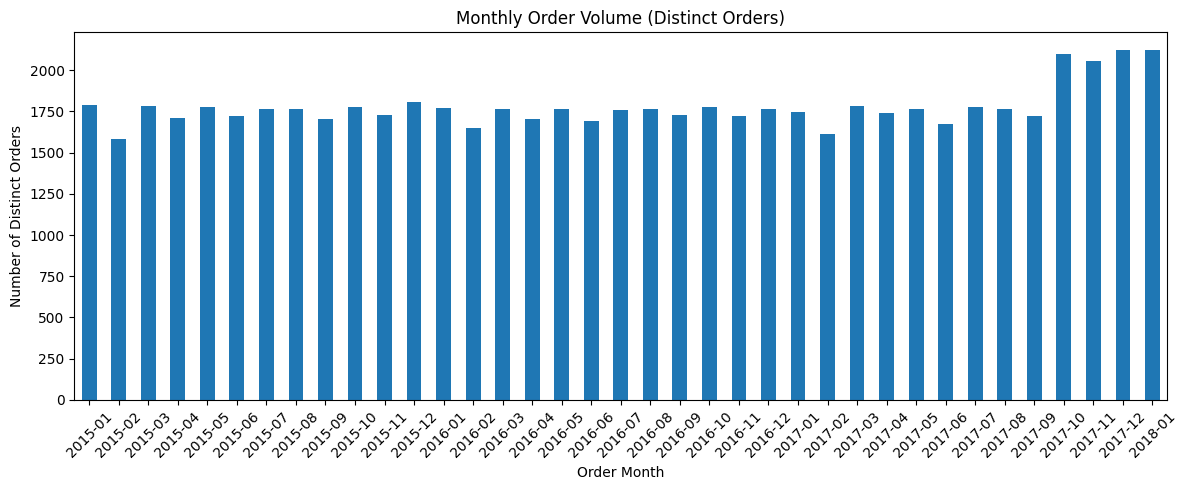

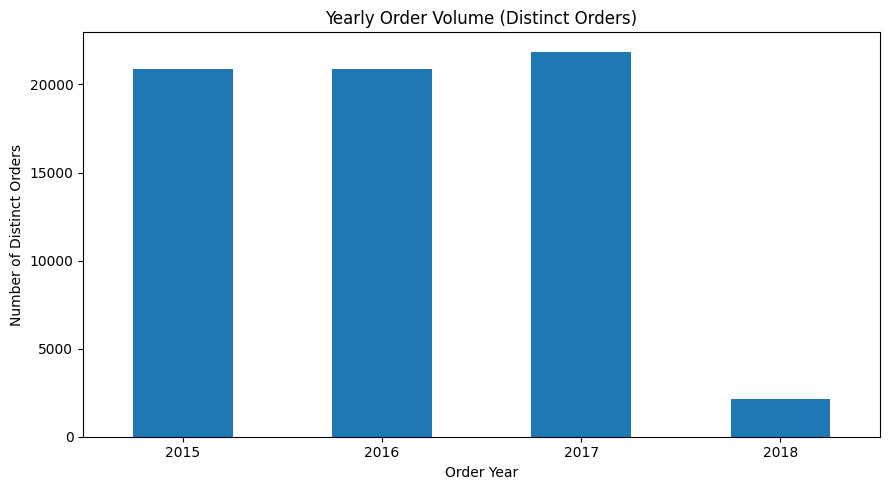

In [10]:
if order_col and order_date_col:
    date_work = valid_order_rows[
        ["_order_key", order_date_col]
    ].copy()

    date_work["_parsed_date"] = pd.to_datetime(
        date_work[order_date_col], errors="coerce"
    )

    order_dates = (
        date_work.dropna(subset=["_parsed_date"])
        .groupby("_order_key")["_parsed_date"]
        .min()
    )

    monthly = (
        order_dates.groupby(order_dates.dt.to_period("M"))
        .size().sort_index()
    )

    yearly = (
        order_dates.groupby(order_dates.dt.year)
        .size().sort_index()
    )

    add_summary("Orders with valid order dates", len(order_dates))
    add_summary("Months represented", len(monthly))
    add_summary("Years represented", len(yearly))

    add_validation(
        "Monthly order counts reconcile",
        len(order_dates), int(monthly.sum()),
        len(order_dates) == int(monthly.sum()),
        "Each order is assigned to one month."
    )

    add_validation(
        "Yearly order counts reconcile",
        len(order_dates), int(yearly.sum()),
        len(order_dates) == int(yearly.sum()),
        "Each order is assigned to one year."
    )

    if not monthly.empty:
        fig, ax = plt.subplots(figsize=(12, 5))
        monthly.index = monthly.index.astype(str)
        monthly.plot(kind="bar", ax=ax)
        ax.set_title("Monthly Order Volume (Distinct Orders)")
        ax.set_xlabel("Order Month")
        ax.set_ylabel("Number of Distinct Orders")
        ax.tick_params(axis="x", rotation=45)
        fig.tight_layout()
        fig.savefig(
            OUT / "monthly_order_volume.png",
            dpi=160, bbox_inches="tight"
        )
        plt.show()
        plt.close(fig)

        finding_rows.append(
            f"Highest monthly order volume: {monthly.idxmax()} "
            f"with {int(monthly.max()):,} distinct orders."
        )

    if not yearly.empty:
        fig, ax = plt.subplots(figsize=(9, 5))
        yearly.plot(kind="bar", ax=ax)
        ax.set_title("Yearly Order Volume (Distinct Orders)")
        ax.set_xlabel("Order Year")
        ax.set_ylabel("Number of Distinct Orders")
        ax.tick_params(axis="x", rotation=0)
        fig.tight_layout()
        fig.savefig(
            OUT / "yearly_order_volume.png",
            dpi=160, bbox_inches="tight"
        )
        plt.show()
        plt.close(fig)
else:
    add_summary("Order volume", "Not calculated",
                "Order ID or order date column was not found.")


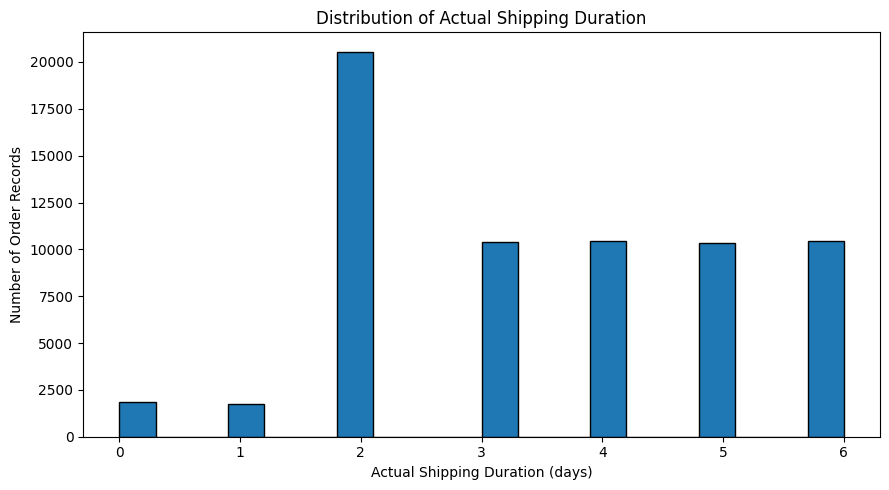

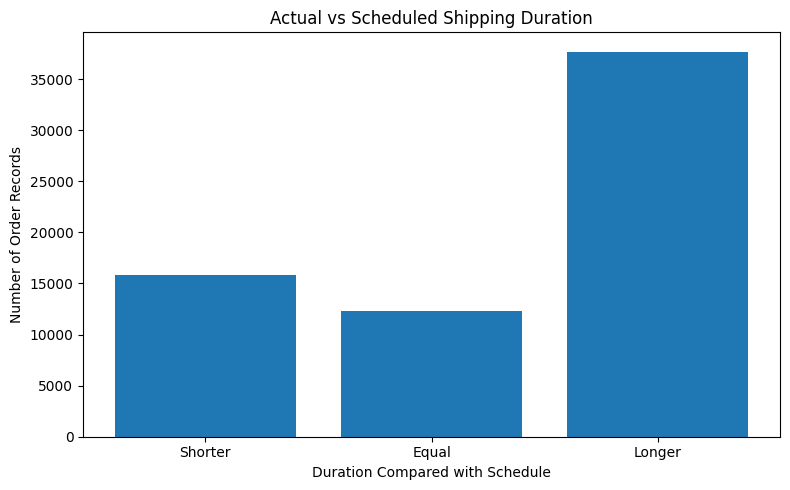

Cell 4 completed successfully.


In [22]:


if "order_df" not in globals():
    if "df" in globals():
        if order_col:

            order_df = df.drop_duplicates(subset=[order_col])
        else:
            order_df = df.copy()
    else:
        order_df = pd.DataFrame()

if real_days_col and real_days_col in order_df.columns:

    real_days = pd.to_numeric(
        order_df[real_days_col], errors="coerce"
    ).dropna()

    add_summary(
        "Orders with valid actual shipping days",
        len(real_days)
    )

    if not real_days.empty:

        add_summary(
            "Mean actual shipping duration (days)",
            round(real_days.mean(), 3)
        )
        add_summary(
            "Median actual shipping duration (days)",
            round(real_days.median(), 3)
        )
        add_summary(
            "Minimum actual shipping duration (days)",
            round(real_days.min(), 3)
        )
        add_summary(
            "Maximum actual shipping duration (days)",
            round(real_days.max(), 3)
        )

        fig, ax = plt.subplots(figsize=(9, 5))
        ax.hist(real_days, bins=20, edgecolor="black")
        ax.set_title("Distribution of Actual Shipping Duration")
        ax.set_xlabel("Actual Shipping Duration (days)")
        ax.set_ylabel("Number of Order Records")
        fig.tight_layout()
        fig.savefig(
            OUT / "delivery_duration.png",
            dpi=160,
            bbox_inches="tight"
        )
        plt.show()
        plt.close(fig)

        finding_rows.append(
            f"Mean actual shipping duration was "
            f"{real_days.mean():.2f} days across "
            f"{len(real_days):,} records with valid values."
        )

    else:
        add_summary(
            "Actual shipping duration",
            "Not calculated",
            "No valid numeric values were found."
        )

else:
    add_summary(
        "Actual shipping duration",
        "Not calculated",
        "The actual shipping-days column was not found."
    )


# Compare actual duration with scheduled duration.
if (
    real_days_col
    and scheduled_days_col
    and real_days_col in order_df.columns
    and scheduled_days_col in order_df.columns
):

    comparison = pd.DataFrame({
        "actual": pd.to_numeric(
            order_df[real_days_col], errors="coerce"
        ),
        "scheduled": pd.to_numeric(
            order_df[scheduled_days_col], errors="coerce"
        )
    }).dropna()

    if not comparison.empty:

        difference = comparison["actual"] - comparison["scheduled"]

        earlier = int((difference < 0).sum())
        same = int((difference == 0).sum())
        later = int((difference > 0).sum())

        add_summary(
            "Orders in actual-vs-scheduled comparison",
            len(comparison)
        )
        add_summary("Actual duration shorter than scheduled", earlier)
        add_summary("Actual duration equal to scheduled", same)
        add_summary("Actual duration longer than scheduled", later)

        add_validation(
            "Delivery categories reconcile",
            len(comparison),
            earlier + same + later,
            len(comparison) == earlier + same + later
        )

        fig, ax = plt.subplots(figsize=(8, 5))
        ax.bar(
            ["Shorter", "Equal", "Longer"],
            [earlier, same, later]
        )
        ax.set_title("Actual vs Scheduled Shipping Duration")
        ax.set_xlabel("Duration Compared with Schedule")
        ax.set_ylabel("Number of Order Records")
        fig.tight_layout()
        fig.savefig(
            OUT / "actual_vs_scheduled_delivery.png",
            dpi=160,
            bbox_inches="tight"
        )
        plt.show()
        plt.close(fig)

    else:
        add_summary(
            "Actual-vs-scheduled comparison",
            "Not calculated",
            "No records have both numeric duration values."
        )

else:
    add_summary(
        "Actual-vs-scheduled comparison",
        "Not calculated",
        "One or both duration columns are unavailable."
    )

print("Cell 4 completed successfully.")

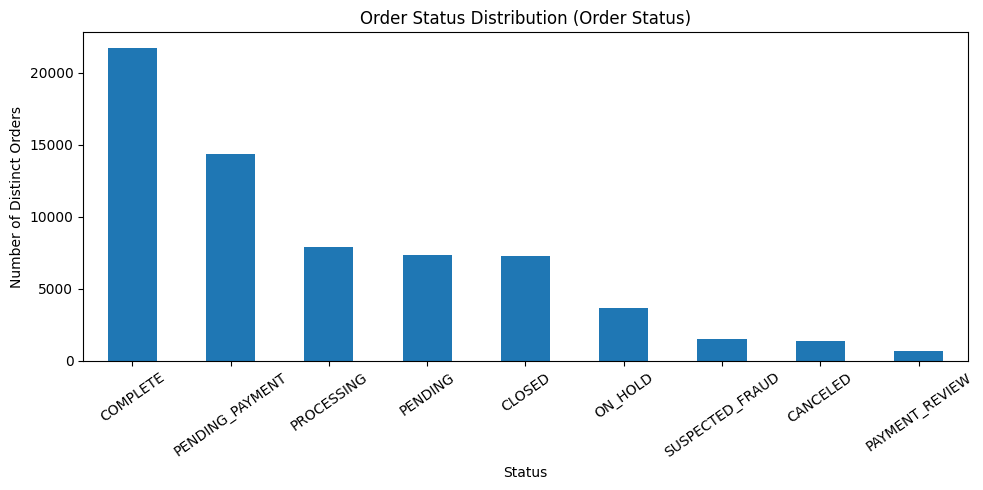

In [23]:

if status_col or delivery_status_col:
    status_source = status_col or delivery_status_col

    if order_col and status_col:
        status_variation = (
            valid_order_rows.dropna(subset=[status_col])
            .groupby("_order_key")[status_col]
            .nunique()
        )
        conflicts = int((status_variation > 1).sum())

        add_summary(
            "Orders with multiple order-status values",
            conflicts,
            "Potential status conflicts across item rows."
        )

    status_counts = (
        order_df[status_source]
        .astype("string")
        .fillna("Missing")
        .value_counts()
        .sort_values(ascending=False)
    )

    denominator = len(order_df)

    fig, ax = plt.subplots(figsize=(10, 5))
    status_counts.plot(kind="bar", ax=ax)
    ax.set_title(f"Order Status Distribution ({status_source})")
    ax.set_xlabel("Status")
    ax.set_ylabel(
        "Number of Distinct Orders" if order_col else "Number of Rows"
    )
    ax.tick_params(axis="x", rotation=35)
    fig.tight_layout()
    fig.savefig(
        OUT / "order_status_distribution.png",
        dpi=160, bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

    add_validation(
        "Order-status chart counts reconcile",
        denominator, int(status_counts.sum()),
        denominator == int(status_counts.sum()),
        "Missing statuses are included."
    )

    cancelled_mask = pd.Series(False, index=order_df.index)

    for col in [status_col, delivery_status_col]:
        if col:
            cancelled_mask |= (
                order_df[col].astype("string")
                .str.contains("cancel", case=False, na=False)
            )

    cancelled_count = int(cancelled_mask.sum())
    cancellation_rate = (
        cancelled_count / denominator * 100
        if denominator else np.nan
    )

    add_summary("Orders classified as cancelled", cancelled_count)
    add_summary(
        "Order-level cancellation rate (%)",
        round(cancellation_rate, 3)
        if pd.notna(cancellation_rate) else "N/A",
        "Uses explicit 'cancel' text in available status fields."
    )

    add_validation(
        "Cancelled count is within order denominator",
        f"0 to {denominator}",
        cancelled_count,
        0 <= cancelled_count <= denominator
    )

    finding_rows.append(
        f"{cancelled_count:,} of {denominator:,} orders were classified "
        "as cancelled using the stated status-text rule."
    )
else:
    add_summary("Cancellation analysis", "Not calculated",
                "No recognized status column was found.")


In [13]:
key_columns = [
    c for c in [
        order_col, item_col, order_date_col, shipping_date_col,
        status_col, delivery_status_col, real_days_col,
        scheduled_days_col
    ] if c
]

missing_df = pd.DataFrame({
    "Column": key_columns,
    "Missing Values": [int(df[c].isna().sum()) for c in key_columns],
    "Missing Percentage": [
        round(df[c].isna().mean() * 100, 3)
        for c in key_columns
    ]
})

if not finding_rows:
    finding_rows.append(
        "No findings were generated. Review detected columns and data quality."
    )

finding_rows.append(
    "Customer-rating analysis was excluded because no suitable "
    "customer-rating field was identified for this analysis."
)
finding_rows.append(
    "Order-level metrics use distinct order IDs to avoid counting "
    "multi-item orders multiple times."
)

summary_df = pd.DataFrame(summary_rows)
validation_df = pd.DataFrame(validation_rows)
findings_df = pd.DataFrame({
    "Key Observations and Limitations": finding_rows
})

xlsx_path = OUT / "Validated_EDA_Findings.xlsx"

with pd.ExcelWriter(xlsx_path, engine="openpyxl") as writer:
    summary_df.to_excel(writer, sheet_name="Summary", index=False)
    findings_df.to_excel(writer, sheet_name="Findings", index=False)
    validation_df.to_excel(
        writer, sheet_name="Chart Validation", index=False
    )
    missing_df.to_excel(
        writer, sheet_name="Missing Values", index=False
    )

validation_path = OUT / "chart_validation_results.csv"
validation_df.to_csv(validation_path, index=False)

print("Excel report created:", xlsx_path)
print("Validation file created:", validation_path)

print("\nSummary:")
display(summary_df)

print("\nChart validation:")
display(validation_df)

print("\nFindings:")
display(findings_df)


Excel report created: /content/EDA_Outputs/Validated_EDA_Findings.xlsx
Validation file created: /content/EDA_Outputs/chart_validation_results.csv

Summary:


,Metric,Value,Notes
0,Analysis dataset,DataCo_Cleaned_Interim.csv,
1,Raw dataset rows,180519,
2,Cleaned dataset rows,180519,
3,Raw dataset columns,53,
4,Cleaned dataset columns,53,
5,Exact duplicate rows in cleaned data,0,
6,Customer rating analysis,Excluded,No suitable customer-rating column is being an...
7,Orders with valid order dates,65752,
8,Months represented,37,
9,Years represented,4,



Chart validation:


,Check,Expected,Actual,Passed,Notes
0,Raw and cleaned row counts match,180519,180519,True,Matching row counts do not prove every value i...
1,Raw and cleaned column counts match,53,53,True,
2,Monthly order counts reconcile,65752,65752,True,Each order is assigned to one month.
3,Yearly order counts reconcile,65752,65752,True,Each order is assigned to one year.



Findings:


,Key Observations and Limitations
0,"Highest monthly order volume: 2017-12 with 2,1..."
1,Customer-rating analysis was excluded because ...
2,Order-level metrics use distinct order IDs to ...


In [25]:
deliverables = [
    OUT / "Validated_EDA_Findings.xlsx",
    OUT / "chart_validation_results.csv",
    *sorted(OUT.glob("*.png"))
]

for path in deliverables:
    if path.exists():
        print("Downloading:", path.name)
        files.download(str(path))


Downloading: Validated_EDA_Findings.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: chart_validation_results.csv


<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: yearly_order_volume.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>